In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load grid nodes
grid_nodes = pd.read_csv("data/chicago_spatial_grid.csv")

# Load KDE results
kde_results = pd.read_csv("data/kde_results.csv")

print("Grid nodes:", grid_nodes.shape)
print("KDE results:", kde_results.shape)

display(kde_results.head())

Grid nodes: (157, 6)
KDE results: (157, 8)


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_FREQUENCY,KDE_DENSITY,KDE_SCORE,KDE_HOTSPOT,CRIME_HOTSPOT
0,0_10,41.654305,-87.617586,595,0.024085,0.075125,0,0
1,0_11,41.654444,-87.591166,559,0.015136,0.046966,0,0
2,0_12,41.654577,-87.564745,121,0.002881,0.008406,0,0
3,0_13,41.654704,-87.538324,451,0.013267,0.041087,0,0
4,0_9,41.654160,-87.644006,218,0.012107,0.037436,0,0


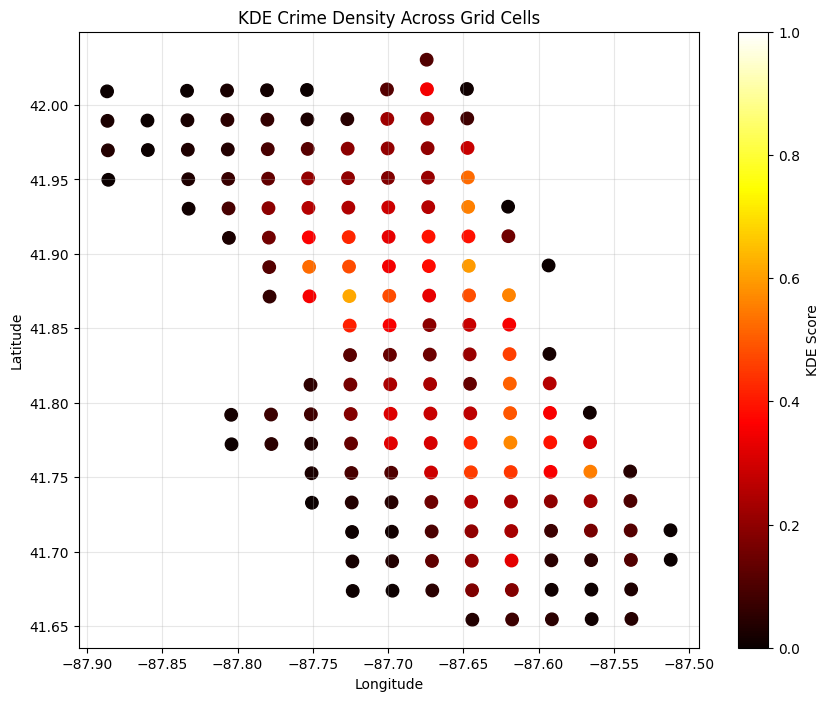

In [3]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    kde_results["GRID_CENTER_LON"],
    kde_results["GRID_CENTER_LAT"],
    c=kde_results["KDE_SCORE"],
    cmap="hot",
    s=80
)

plt.colorbar(scatter, label="KDE Score")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("KDE Crime Density Across Grid Cells")

plt.grid(alpha=0.3)
plt.show()

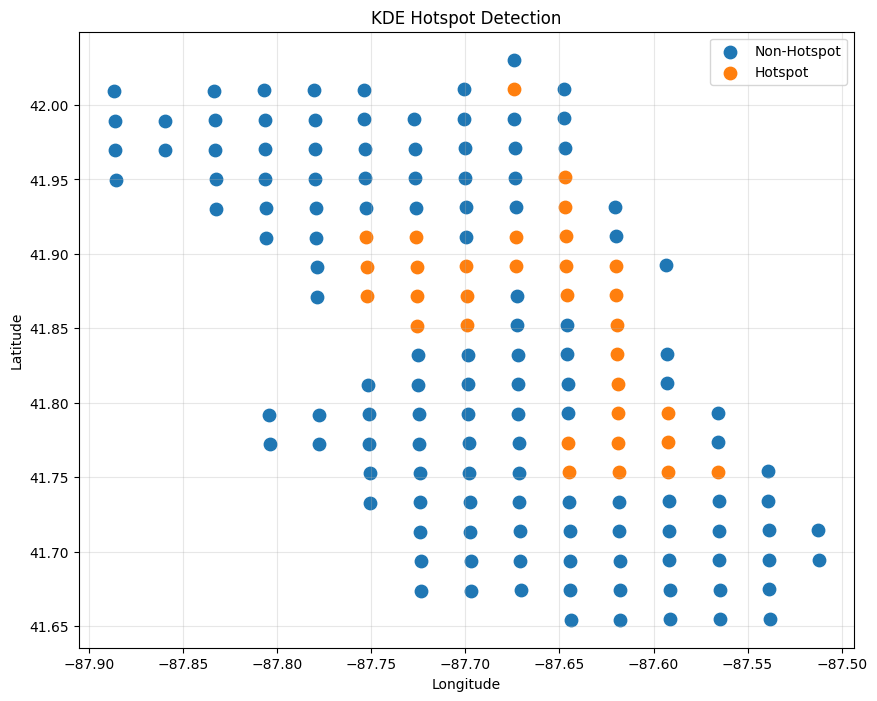

In [4]:
plt.figure(figsize=(10, 8))

for label, name in [(0, "Non-Hotspot"), (1, "Hotspot")]:
    subset = kde_results[kde_results["KDE_HOTSPOT"] == label]
    
    plt.scatter(
        subset["GRID_CENTER_LON"],
        subset["GRID_CENTER_LAT"],
        s=80,
        label=name
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("KDE Hotspot Detection")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
hotspot_counts = kde_results["KDE_HOTSPOT"].value_counts()

print("KDE hotspot distribution:")
print(hotspot_counts)

print("\nNumber of hotspot cells:",
      (kde_results["KDE_HOTSPOT"] == 1).sum())

print("Number of non-hotspot cells:",
      (kde_results["KDE_HOTSPOT"] == 0).sum())

KDE hotspot distribution:
KDE_HOTSPOT
0    125
1     32
Name: count, dtype: int64

Number of hotspot cells: 32
Number of non-hotspot cells: 125


In [6]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    kde_results["CRIME_HOTSPOT"],
    kde_results["KDE_HOTSPOT"]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[121   4]
 [  4  28]]


In [7]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 121
False Positives: 4
False Negatives: 4
True Positives : 28


In [8]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(
    kde_results["CRIME_HOTSPOT"],
    kde_results["KDE_HOTSPOT"]
)

print("Cohen's Kappa:", round(kappa, 4))

Cohen's Kappa: 0.843


In [9]:
top_kde = kde_results.sort_values(
    "KDE_SCORE",
    ascending=False
).head(20)

display(
    top_kde[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "CRIME_FREQUENCY",
            "KDE_DENSITY",
            "KDE_SCORE",
            "KDE_HOTSPOT"
        ]
    ]
)

,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_FREQUENCY,KDE_DENSITY,KDE_SCORE,KDE_HOTSPOT
17,12_10,41.892077,-87.619871,9549,0.318023,1.000000,1
13,11_6,41.871642,-87.725717,4868,0.195962,0.615935,1
24,12_9,41.891930,-87.646389,4586,0.189243,0.594794,1
124,6_10,41.773192,-87.618725,4464,0.181087,0.569131,1
10,11_10,41.872263,-87.619680,4467,0.178537,0.561106,1
41,14_9,41.931558,-87.646789,3810,0.176837,0.555758,1
117,5_12,41.753650,-87.565613,3960,0.175298,0.550918,1
20,12_5,41.891284,-87.752459,3621,0.167755,0.527181,1
50,15_9,41.951371,-87.646989,3027,0.167490,0.526349,1
144,8_10,41.812821,-87.619106,3389,0.161896,0.508747,1


In [10]:
correlation = kde_results[
    ["CRIME_FREQUENCY", "KDE_DENSITY"]
].corr().iloc[0, 1]

print("Crime Frequency vs KDE Density Correlation:",
      round(correlation, 4))

Crime Frequency vs KDE Density Correlation: 0.9787


In [11]:
comparison_summary = pd.DataFrame({
    "Metric": [
        "KDE Accuracy",
        "KDE Precision",
        "KDE Recall",
        "KDE F1",
        "Crime Frequency vs KDE Correlation",
        "Number of Grid Cells",
        "Number of KDE Hotspots"
    ],
    "Value": [
        0.9490,
        0.8750,
        0.8750,
        0.8750,
        correlation,
        len(kde_results),
        int(kde_results["KDE_HOTSPOT"].sum())
    ]
})

display(comparison_summary)

,Metric,Value
0,KDE Accuracy,0.949000
1,KDE Precision,0.875000
2,KDE Recall,0.875000
3,KDE F1,0.875000
4,Crime Frequency vs KDE Correlation,0.978681
5,Number of Grid Cells,157.000000
6,Number of KDE Hotspots,32.000000


In [12]:
comparison_summary.to_csv(
    "data/kde_comparison_summary.csv",
    index=False
)

print("Saved: data/kde_comparison_summary.csv")

Saved: data/kde_comparison_summary.csv
